In [1]:
import pandas as pd
import numpy as np

# Load the labelled dataset
df = pd.read_csv("../data/processed/kerala_flood_labelled.csv")

# Sort chronologically
df = df.sort_values("YEAR").reset_index(drop=True)

# Recreate our chronological 70:30 split
split_index = round(len(df) * 0.70)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining flood cases:", train_df["FLOOD"].sum())
print("Testing flood cases:", test_df["FLOOD"].sum())

Training shape: (82, 20)
Testing shape: (35, 20)

Training flood cases: 3
Testing flood cases: 3


In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Separate input features and target
feature_columns = ["JAN", "FEB", "MAR", "APR", "MAY"]

X_train = train_df[feature_columns]
y_train = train_df["FLOOD"]

X_test = test_df[feature_columns]
y_test = test_df["FLOOD"]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (82, 5)
Testing features: (35, 5)
Training labels: (82,)
Testing labels: (35,)


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print(lr_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define 3-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Perform cross-validation
lr_cv_results = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = lr_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 1.]
Mean score: 0.3333333333333333

F1
Fold scores: [0.         0.         0.16666667]
Mean score: 0.05555555555555555

ROC_AUC
Fold scores: [0.07407407 0.34615385 0.80769231]
Mean score: 0.409306742640076


In [5]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train on the complete training dataset
lr_pipeline.fit(X_train, y_train)

# Generate predictions
y_pred = lr_pipeline.predict(X_test)

# Get flood probabilities for ROC-AUC
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Logistic Regression - Test Results")

print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Logistic Regression - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.3229166666666667

Confusion Matrix:
[[23  9]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.72      0.79        32
           1       0.00      0.00      0.00         3

    accuracy                           0.66        35
   macro avg       0.44      0.36      0.40        35
weighted avg       0.81      0.66      0.73        35



In [6]:
lr_test_results = test_df[["YEAR", "FLOOD"]].copy()

lr_test_results["PREDICTED_FLOOD"] = y_pred
lr_test_results["FLOOD_PROBABILITY"] = y_prob.round(3)

print(
    lr_test_results[lr_test_results["FLOOD"] == 1]
)

     YEAR  FLOOD  PREDICTED_FLOOD  FLOOD_PROBABILITY
91   1992      1                0              0.119
106  2007      1                0              0.155
112  2013      1                0              0.206


In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
dt_pipeline = Pipeline([
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ))
])

print(dt_pipeline)

Pipeline(steps=[('classifier',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=2,
                                        min_samples_leaf=5, random_state=42))])


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Perform cross-validation
dt_cv_results = cross_validate(
    dt_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = dt_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 0.]
Mean score: 0.0

F1
Fold scores: [0. 0. 0.]
Mean score: 0.0

ROC_AUC
Fold scores: [0.42592593 0.46153846 0.42307692]
Mean score: 0.4368471035137702


In [9]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train on the complete training dataset
dt_pipeline.fit(X_train, y_train)

# Generate predictions
dt_pred = dt_pipeline.predict(X_test)

# Calculate flood probabilities
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Decision Tree - Test Results")

print("Recall:", recall_score(y_test, dt_pred, zero_division=0))
print("F1-score:", f1_score(y_test, dt_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred, zero_division=0))

Decision Tree - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.359375

Confusion Matrix:
[[23  9]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.72      0.79        32
           1       0.00      0.00      0.00         3

    accuracy                           0.66        35
   macro avg       0.44      0.36      0.40        35
weighted avg       0.81      0.66      0.73        35



In [10]:
dt_test_results = test_df[["YEAR", "FLOOD"]].copy()

dt_test_results["PREDICTED_FLOOD"] = dt_pred
dt_test_results["FLOOD_PROBABILITY"] = dt_prob.round(3)

print(dt_test_results[dt_test_results["FLOOD"] == 1])

     YEAR  FLOOD  PREDICTED_FLOOD  FLOOD_PROBABILITY
91   1992      1                0                0.0
106  2007      1                0                0.0
112  2013      1                0                0.0


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create k-NN pipeline
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=3,
        weights="distance"
    ))
])

print(knn_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 KNeighborsClassifier(n_neighbors=3, weights='distance'))])


In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Perform cross-validation
knn_cv_results = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = knn_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 0.]
Mean score: 0.0

F1
Fold scores: [0. 0. 0.]
Mean score: 0.0

ROC_AUC
Fold scores: [0.40740741 0.48076923 0.44230769]
Mean score: 0.44349477682811017


In [13]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train k-NN on the complete training dataset
knn_pipeline.fit(X_train, y_train)

# Generate predictions
knn_pred = knn_pipeline.predict(X_test)

# Calculate flood probabilities
knn_prob = knn_pipeline.predict_proba(X_test)[:, 1]

# Evaluate the model
print("k-NN - Test Results")

print("Recall:", recall_score(y_test, knn_pred, zero_division=0))
print("F1-score:", f1_score(y_test, knn_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, knn_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, knn_pred, zero_division=0))

k-NN - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.484375

Confusion Matrix:
[[32  0]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.96        32
           1       0.00      0.00      0.00         3

    accuracy                           0.91        35
   macro avg       0.46      0.50      0.48        35
weighted avg       0.84      0.91      0.87        35



In [14]:
knn_test_results = test_df[["YEAR", "FLOOD"]].copy()

knn_test_results["PREDICTED_FLOOD"] = knn_pred
knn_test_results["FLOOD_PROBABILITY"] = knn_prob.round(3)

print(knn_test_results[knn_test_results["FLOOD"] == 1])

     YEAR  FLOOD  PREDICTED_FLOOD  FLOOD_PROBABILITY
91   1992      1                0                0.0
106  2007      1                0                0.0
112  2013      1                0                0.0


In [15]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# Create Gaussian Naive Bayes pipeline
gnb_pipeline = Pipeline([
    ("classifier", GaussianNB())
])

print(gnb_pipeline)

Pipeline(steps=[('classifier', GaussianNB())])


In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Perform cross-validation
gnb_cv_results = cross_validate(
    gnb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = gnb_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 0.]
Mean score: 0.0

F1
Fold scores: [0. 0. 0.]
Mean score: 0.0

ROC_AUC
Fold scores: [0.03703704 0.53846154 0.53846154]
Mean score: 0.3713200379867046


In [17]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train on the complete training dataset
gnb_pipeline.fit(X_train, y_train)

# Generate predictions
gnb_pred = gnb_pipeline.predict(X_test)

# Calculate flood probabilities
gnb_prob = gnb_pipeline.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Gaussian Naive Bayes - Test Results")

print("Recall:", recall_score(y_test, gnb_pred, zero_division=0))
print("F1-score:", f1_score(y_test, gnb_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, gnb_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gnb_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, gnb_pred, zero_division=0))

Gaussian Naive Bayes - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.375

Confusion Matrix:
[[32  0]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.96        32
           1       0.00      0.00      0.00         3

    accuracy                           0.91        35
   macro avg       0.46      0.50      0.48        35
weighted avg       0.84      0.91      0.87        35



In [18]:
gnb_test_results = test_df[["YEAR", "FLOOD"]].copy()

gnb_test_results["PREDICTED_FLOOD"] = gnb_pred
gnb_test_results["FLOOD_PROBABILITY"] = gnb_prob.round(3)

print(gnb_test_results[gnb_test_results["FLOOD"] == 1])

     YEAR  FLOOD  PREDICTED_FLOOD  FLOOD_PROBABILITY
91   1992      1                0              0.000
106  2007      1                0              0.007
112  2013      1                0              0.000


In [19]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# Gaussian Naive Bayes with equal class priors
gnb_balanced_pipeline = Pipeline([
    ("classifier", GaussianNB(
        priors=[0.5, 0.5]
    ))
])

print(gnb_balanced_pipeline)

Pipeline(steps=[('classifier', GaussianNB(priors=[0.5, 0.5]))])


In [20]:
# Perform 3-fold stratified cross-validation
gnb_balanced_cv_results = cross_validate(
    gnb_balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = gnb_balanced_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 0.]
Mean score: 0.0

F1
Fold scores: [0. 0. 0.]
Mean score: 0.0

ROC_AUC
Fold scores: [0.03703704 0.53846154 0.53846154]
Mean score: 0.3713200379867046


In [21]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train balanced-prior GNB
gnb_balanced_pipeline.fit(X_train, y_train)

# Generate predictions
gnb_balanced_pred = gnb_balanced_pipeline.predict(X_test)

# Calculate flood probabilities
gnb_balanced_prob = (
    gnb_balanced_pipeline.predict_proba(X_test)[:, 1]
)

# Evaluate the model
print("Balanced-prior Gaussian Naive Bayes - Test Results")

print("Recall:", recall_score(
    y_test, gnb_balanced_pred, zero_division=0
))
print("F1-score:", f1_score(
    y_test, gnb_balanced_pred, zero_division=0
))
print("ROC-AUC:", roc_auc_score(
    y_test, gnb_balanced_prob
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, gnb_balanced_pred, labels=[0, 1]
))

print("\nClassification Report:")
print(classification_report(
    y_test, gnb_balanced_pred, zero_division=0
))

Balanced-prior Gaussian Naive Bayes - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.375

Confusion Matrix:
[[26  6]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.81      0.85        32
           1       0.00      0.00      0.00         3

    accuracy                           0.74        35
   macro avg       0.45      0.41      0.43        35
weighted avg       0.82      0.74      0.78        35



In [22]:
gnb_balanced_results = test_df[["YEAR", "FLOOD"]].copy()

gnb_balanced_results["PREDICTED_FLOOD"] = gnb_balanced_pred
gnb_balanced_results["FLOOD_PROBABILITY"] = (
    gnb_balanced_prob.round(3)
)

print(
    gnb_balanced_results[
        gnb_balanced_results["FLOOD"] == 1
    ]
)

     YEAR  FLOOD  PREDICTED_FLOOD  FLOOD_PROBABILITY
91   1992      1                0              0.000
106  2007      1                0              0.160
112  2013      1                0              0.002


In [23]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        random_state=42
    ))
])

print(svm_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', SVC(class_weight='balanced', random_state=42))])


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Three-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Perform cross-validation
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Display results
for metric in scoring:
    scores = svm_cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold scores:", scores)
    print("Mean score:", scores.mean())


RECALL
Fold scores: [0. 0. 0.]
Mean score: 0.0

F1
Fold scores: [0. 0. 0.]
Mean score: 0.0

ROC_AUC
Fold scores: [0.11111111 0.65384615 0.80769231]
Mean score: 0.5242165242165243


In [25]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train SVM on the complete training dataset
svm_pipeline.fit(X_train, y_train)

# Generate class predictions
svm_pred = svm_pipeline.predict(X_test)

# Generate decision scores for ROC-AUC
svm_scores = svm_pipeline.decision_function(X_test)

# Evaluate the model
print("SVM - Test Results")

print("Recall:", recall_score(
    y_test, svm_pred, zero_division=0
))

print("F1-score:", f1_score(
    y_test, svm_pred, zero_division=0
))

print("ROC-AUC:", roc_auc_score(
    y_test, svm_scores
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, svm_pred, labels=[0, 1]
))

print("\nClassification Report:")
print(classification_report(
    y_test, svm_pred, zero_division=0
))

SVM - Test Results
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.15625

Confusion Matrix:
[[30  2]
 [ 3  0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.92        32
           1       0.00      0.00      0.00         3

    accuracy                           0.86        35
   macro avg       0.45      0.47      0.46        35
weighted avg       0.83      0.86      0.84        35



In [26]:
svm_test_results = test_df[["YEAR", "FLOOD"]].copy()

svm_test_results["PREDICTED_FLOOD"] = svm_pred
svm_test_results["DECISION_SCORE"] = svm_scores.round(3)

print(
    svm_test_results[
        svm_test_results["FLOOD"] == 1
    ]
)

     YEAR  FLOOD  PREDICTED_FLOOD  DECISION_SCORE
91   1992      1                0          -1.879
106  2007      1                0          -1.836
112  2013      1                0          -1.757


In [27]:
# Define the two earlier prediction windows
jan_mar_features = ["JAN", "FEB", "MAR"]
jan_apr_features = ["JAN", "FEB", "MAR", "APR"]

# January-March
X_train_jan_mar = train_df[jan_mar_features]
X_test_jan_mar = test_df[jan_mar_features]

# January-April
X_train_jan_apr = train_df[jan_apr_features]
X_test_jan_apr = test_df[jan_apr_features]

# Display dataset shapes
print("January-March:")
print("Training:", X_train_jan_mar.shape)
print("Testing:", X_test_jan_mar.shape)

print("\nJanuary-April:")
print("Training:", X_train_jan_apr.shape)
print("Testing:", X_test_jan_apr.shape)

January-March:
Training: (82, 3)
Testing: (35, 3)

January-April:
Training: (82, 4)
Testing: (35, 4)


In [28]:
# Store our five baseline classifiers
models = {
    "Logistic Regression": lr_pipeline,
    "Decision Tree": dt_pipeline,
    "k-NN": knn_pipeline,
    "Gaussian Naive Bayes": gnb_pipeline,
    "SVM": svm_pipeline
}

# Store cross-validation results
jan_mar_cv_results = {}

# Evaluate each classifier
for name, model in models.items():

    results = cross_validate(
        model,
        X_train_jan_mar,
        y_train,
        cv=cv,
        scoring=scoring
    )

    jan_mar_cv_results[name] = results

    print(f"\n{name}")

    for metric in scoring:
        scores = results[f"test_{metric}"]

        print(f"{metric.upper()}:")
        print("Fold scores:", scores)
        print("Mean score:", scores.mean().round(3))


Logistic Regression
RECALL:
Fold scores: [0. 0. 1.]
Mean score: 0.333
F1:
Fold scores: [0.    0.    0.125]
Mean score: 0.042
ROC_AUC:
Fold scores: [0.         0.         0.61538462]
Mean score: 0.205

Decision Tree
RECALL:
Fold scores: [0. 0. 0.]
Mean score: 0.0
F1:
Fold scores: [0. 0. 0.]
Mean score: 0.0
ROC_AUC:
Fold scores: [0.38888889 0.40384615 0.42307692]
Mean score: 0.405

k-NN
RECALL:
Fold scores: [0. 0. 0.]
Mean score: 0.0
F1:
Fold scores: [0. 0. 0.]
Mean score: 0.0
ROC_AUC:
Fold scores: [0.38888889 0.44230769 0.46153846]
Mean score: 0.431

Gaussian Naive Bayes
RECALL:
Fold scores: [0. 0. 0.]
Mean score: 0.0
F1:
Fold scores: [0. 0. 0.]
Mean score: 0.0
ROC_AUC:
Fold scores: [0.07407407 0.30769231 0.61538462]
Mean score: 0.332

SVM
RECALL:
Fold scores: [0. 0. 0.]
Mean score: 0.0
F1:
Fold scores: [0. 0. 0.]
Mean score: 0.0
ROC_AUC:
Fold scores: [0.11111111 0.73076923 0.46153846]
Mean score: 0.434


In [29]:
jan_mar_summary = []

for name, results in jan_mar_cv_results.items():

    jan_mar_summary.append({
        "Model": name,
        "Recall": results["test_recall"].mean(),
        "F1-score": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    })

jan_mar_summary = pd.DataFrame(jan_mar_summary)

print(jan_mar_summary.round(3).to_string(index=False))

               Model  Recall  F1-score  ROC-AUC
 Logistic Regression   0.333     0.042    0.205
       Decision Tree   0.000     0.000    0.405
                k-NN   0.000     0.000    0.431
Gaussian Naive Bayes   0.000     0.000    0.332
                 SVM   0.000     0.000    0.434


In [30]:
# Store January-April CV results
jan_apr_cv_results = {}

# Evaluate all five classifiers
for name, model in models.items():

    results = cross_validate(
        model,
        X_train_jan_apr,
        y_train,
        cv=cv,
        scoring=scoring
    )

    jan_apr_cv_results[name] = results

# Create a compact comparison table
jan_apr_summary = []

for name, results in jan_apr_cv_results.items():

    jan_apr_summary.append({
        "Model": name,
        "Recall": results["test_recall"].mean(),
        "F1-score": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    })

jan_apr_summary = pd.DataFrame(jan_apr_summary)

print(jan_apr_summary.round(3).to_string(index=False))

               Model  Recall  F1-score  ROC-AUC
 Logistic Regression   0.333     0.039    0.167
       Decision Tree   0.000     0.000    0.405
                k-NN   0.000     0.000    0.425
Gaussian Naive Bayes   0.000     0.000    0.358
                 SVM   0.000     0.000    0.435


In [31]:
from sklearn.metrics import (
    recall_score,
    f1_score,
    roc_auc_score
)

jan_apr_test_results = []
jan_apr_predictions = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_jan_apr, y_train)

    # Predict classes
    predictions = model.predict(X_test_jan_apr)

    # Get continuous scores for ROC-AUC
    if name == "SVM":
        scores = model.decision_function(X_test_jan_apr)
    else:
        scores = model.predict_proba(X_test_jan_apr)[:, 1]

    # Calculate metrics
    jan_apr_test_results.append({
        "Model": name,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

    jan_apr_predictions[name] = predictions

# Display comparison
jan_apr_test_summary = pd.DataFrame(jan_apr_test_results)

print(jan_apr_test_summary.round(3).to_string(index=False))

               Model  Recall  F1-score  ROC-AUC
 Logistic Regression   0.333     0.143    0.354
       Decision Tree   0.000     0.000    0.250
                k-NN   0.000     0.000    0.500
Gaussian Naive Bayes   0.000     0.000    0.375
                 SVM   0.000     0.000    0.167


In [32]:
from sklearn.metrics import confusion_matrix

lr_jan_apr_pred = jan_apr_predictions["Logistic Regression"]

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    lr_jan_apr_pred,
    labels=[0, 1]
))

lr_jan_apr_check = test_df[["YEAR", "FLOOD"]].copy()

lr_jan_apr_check["PREDICTED_FLOOD"] = lr_jan_apr_pred

print("\nDocumented flood-year predictions:")
print(lr_jan_apr_check[lr_jan_apr_check["FLOOD"] == 1])

Confusion Matrix:
[[22 10]
 [ 2  1]]

Documented flood-year predictions:
     YEAR  FLOOD  PREDICTED_FLOOD
91   1992      1                0
106  2007      1                0
112  2013      1                1


In [33]:
jan_mar_test_results = []
jan_mar_predictions = {}

for name, model in models.items():

    model.fit(X_train_jan_mar, y_train)

    predictions = model.predict(X_test_jan_mar)

    if name == "SVM":
        scores = model.decision_function(X_test_jan_mar)
    else:
        scores = model.predict_proba(X_test_jan_mar)[:, 1]

    jan_mar_test_results.append({
        "Model": name,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

    jan_mar_predictions[name] = predictions

jan_mar_test_summary = pd.DataFrame(jan_mar_test_results)

print(jan_mar_test_summary.round(3).to_string(index=False))

               Model  Recall  F1-score  ROC-AUC
 Logistic Regression   0.333     0.154    0.333
       Decision Tree   0.000     0.000    0.250
                k-NN   0.000     0.000    0.453
Gaussian Naive Bayes   0.000     0.000    0.292
                 SVM   0.000     0.000    0.292


In [34]:
jan_may_test_results = []

for name, model in models.items():

    # Train using January-May features
    model.fit(X_train, y_train)

    # Generate predictions
    predictions = model.predict(X_test)

    # Obtain continuous scores
    if name == "SVM":
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)[:, 1]

    jan_may_test_results.append({
        "Model": name,
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

jan_may_test_summary = pd.DataFrame(jan_may_test_results)

print(jan_may_test_summary.round(3).to_string(index=False))

               Model  Recall  F1-score  ROC-AUC
 Logistic Regression     0.0       0.0    0.323
       Decision Tree     0.0       0.0    0.359
                k-NN     0.0       0.0    0.484
Gaussian Naive Bayes     0.0       0.0    0.375
                 SVM     0.0       0.0    0.156


In [35]:
# Combine the three prediction-window results
all_test_results = pd.concat([
    jan_mar_test_summary.assign(
        Prediction_Window="January-March"
    ),
    jan_apr_test_summary.assign(
        Prediction_Window="January-April"
    ),
    jan_may_test_summary.assign(
        Prediction_Window="January-May"
    )
], ignore_index=True)

# Organise the columns
all_test_results = all_test_results[
    ["Prediction_Window", "Model", "Recall", "F1-score", "ROC-AUC"]
]

print(all_test_results.round(3).to_string(index=False))

Prediction_Window                Model  Recall  F1-score  ROC-AUC
    January-March  Logistic Regression   0.333     0.154    0.333
    January-March        Decision Tree   0.000     0.000    0.250
    January-March                 k-NN   0.000     0.000    0.453
    January-March Gaussian Naive Bayes   0.000     0.000    0.292
    January-March                  SVM   0.000     0.000    0.292
    January-April  Logistic Regression   0.333     0.143    0.354
    January-April        Decision Tree   0.000     0.000    0.250
    January-April                 k-NN   0.000     0.000    0.500
    January-April Gaussian Naive Bayes   0.000     0.000    0.375
    January-April                  SVM   0.000     0.000    0.167
      January-May  Logistic Regression   0.000     0.000    0.323
      January-May        Decision Tree   0.000     0.000    0.359
      January-May                 k-NN   0.000     0.000    0.484
      January-May Gaussian Naive Bayes   0.000     0.000    0.375
      Janu

In [36]:
# Collect January-May CV results
jan_may_cv_models = {
    "Logistic Regression": lr_cv_results,
    "Decision Tree": dt_cv_results,
    "k-NN": knn_cv_results,
    "Gaussian Naive Bayes": gnb_cv_results,
    "SVM": svm_cv_results
}

jan_may_cv_summary = []

for name, results in jan_may_cv_models.items():

    jan_may_cv_summary.append({
        "Model": name,
        "Recall": results["test_recall"].mean(),
        "F1-score": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean()
    })

jan_may_cv_summary = pd.DataFrame(jan_may_cv_summary)

# Combine all three CV windows
all_cv_results = pd.concat([
    jan_mar_summary.assign(
        Prediction_Window="January-March"
    ),
    jan_apr_summary.assign(
        Prediction_Window="January-April"
    ),
    jan_may_cv_summary.assign(
        Prediction_Window="January-May"
    )
], ignore_index=True)

all_cv_results = all_cv_results[
    ["Prediction_Window", "Model", "Recall", "F1-score", "ROC-AUC"]
]

print(all_cv_results.round(3).to_string(index=False))

Prediction_Window                Model  Recall  F1-score  ROC-AUC
    January-March  Logistic Regression   0.333     0.042    0.205
    January-March        Decision Tree   0.000     0.000    0.405
    January-March                 k-NN   0.000     0.000    0.431
    January-March Gaussian Naive Bayes   0.000     0.000    0.332
    January-March                  SVM   0.000     0.000    0.434
    January-April  Logistic Regression   0.333     0.039    0.167
    January-April        Decision Tree   0.000     0.000    0.405
    January-April                 k-NN   0.000     0.000    0.425
    January-April Gaussian Naive Bayes   0.000     0.000    0.358
    January-April                  SVM   0.000     0.000    0.435
      January-May  Logistic Regression   0.333     0.056    0.409
      January-May        Decision Tree   0.000     0.000    0.437
      January-May                 k-NN   0.000     0.000    0.443
      January-May Gaussian Naive Bayes   0.000     0.000    0.371
      Janu

In [37]:
from pathlib import Path

# Create results directory if necessary
results_dir = Path("../results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save cross-validation results
all_cv_results.to_csv(
    results_dir / "cross_validation_comparison.csv",
    index=False
)

# Save chronological test results
all_test_results.to_csv(
    results_dir / "test_comparison.csv",
    index=False
)

print("Results saved successfully!")

# Verify saved files
for file in results_dir.glob("*.csv"):
    print(file.name, "-", file.stat().st_size, "bytes")

Results saved successfully!
cross_validation_comparison.csv - 961 bytes
test_comparison.csv - 817 bytes


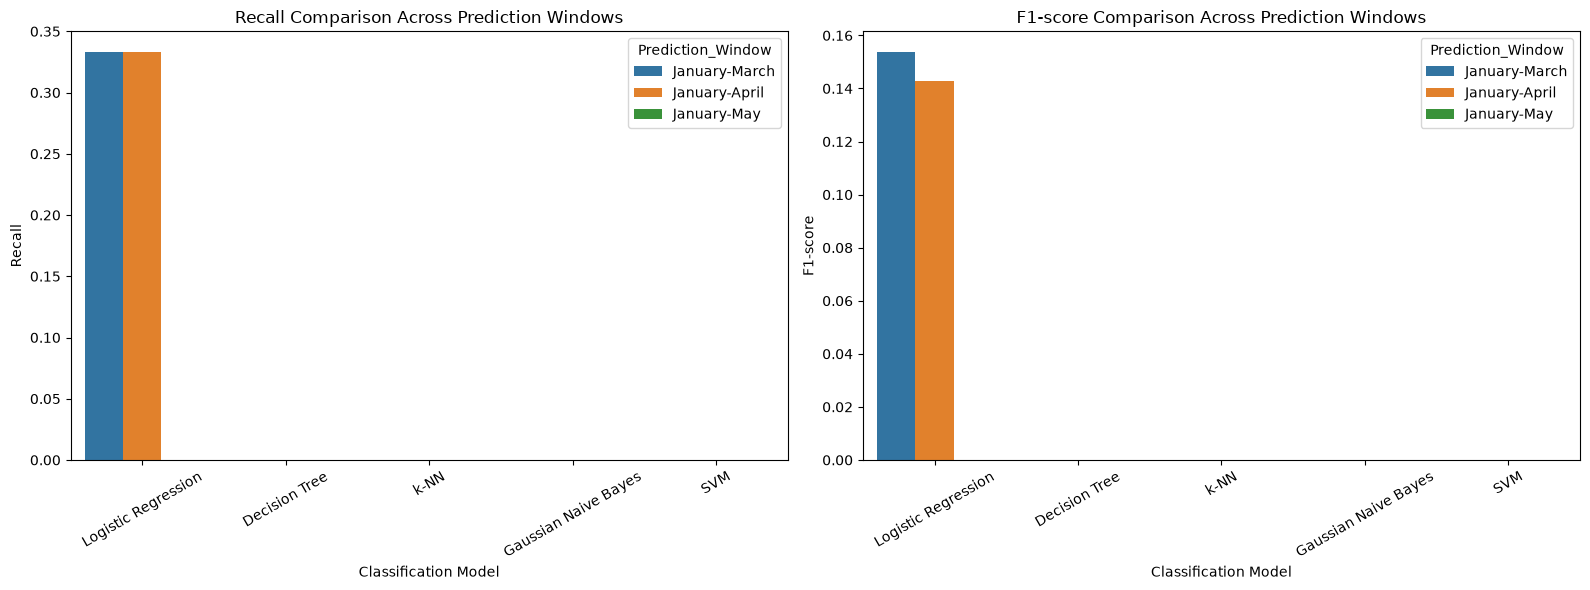

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create two comparison plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Recall comparison
sns.barplot(
    data=all_test_results,
    x="Model",
    y="Recall",
    hue="Prediction_Window",
    ax=axes[0]
)

axes[0].set_title("Recall Comparison Across Prediction Windows")
axes[0].set_xlabel("Classification Model")
axes[0].set_ylabel("Recall")
axes[0].tick_params(axis="x", rotation=30)

# F1-score comparison
sns.barplot(
    data=all_test_results,
    x="Model",
    y="F1-score",
    hue="Prediction_Window",
    ax=axes[1]
)

axes[1].set_title("F1-score Comparison Across Prediction Windows")
axes[1].set_xlabel("Classification Model")
axes[1].set_ylabel("F1-score")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()

# Save figure
plt.savefig(
    "../figures/05_test_recall_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

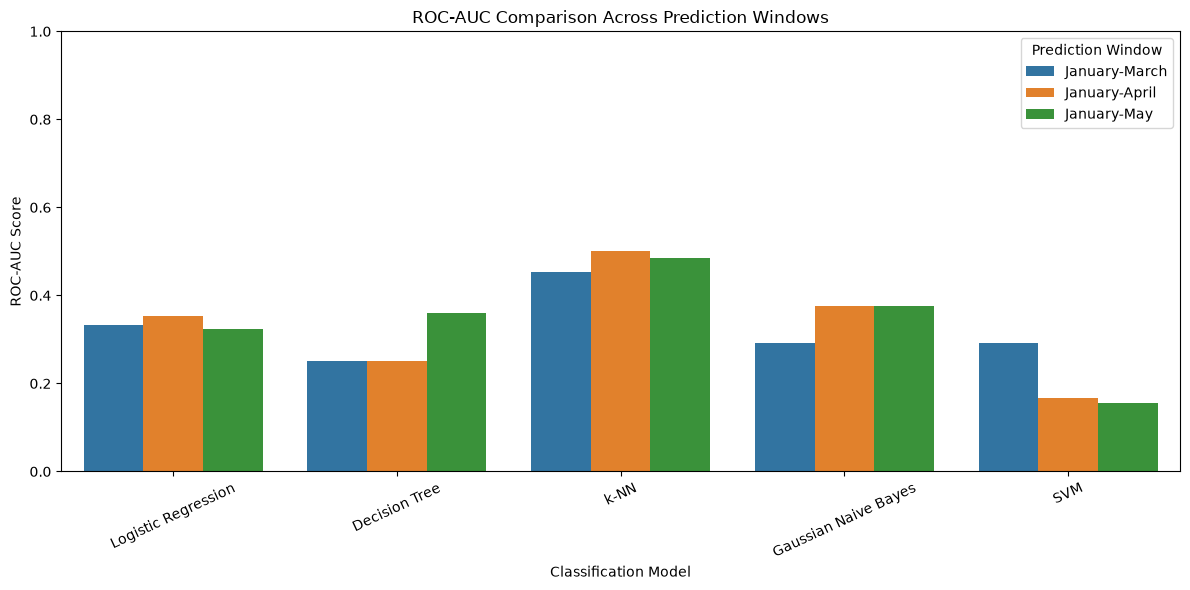

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=all_test_results,
    x="Model",
    y="ROC-AUC",
    hue="Prediction_Window"
)

plt.title("ROC-AUC Comparison Across Prediction Windows")
plt.xlabel("Classification Model")
plt.ylabel("ROC-AUC Score")

plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend(title="Prediction Window")

plt.tight_layout()

plt.savefig(
    "../figures/06_test_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

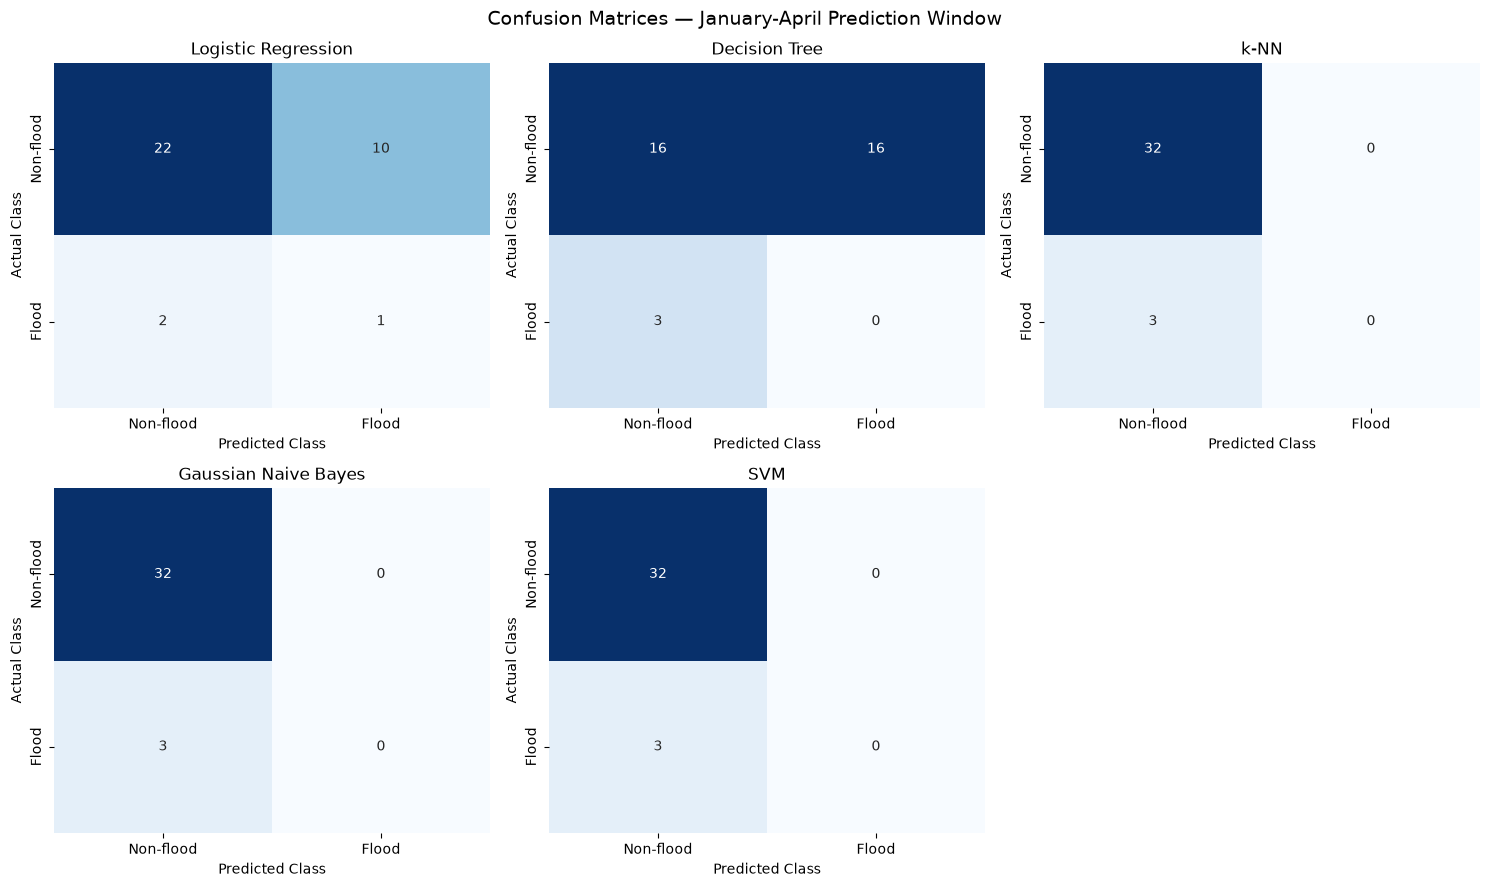

In [40]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, predictions) in zip(
    axes.flat, jan_apr_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Non-flood", "Flood"],
        yticklabels=["Non-flood", "Flood"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

# Hide the unused sixth subplot
axes.flat[-1].axis("off")

plt.suptitle(
    "Confusion Matrices — January-April Prediction Window",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "../figures/07_jan_apr_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

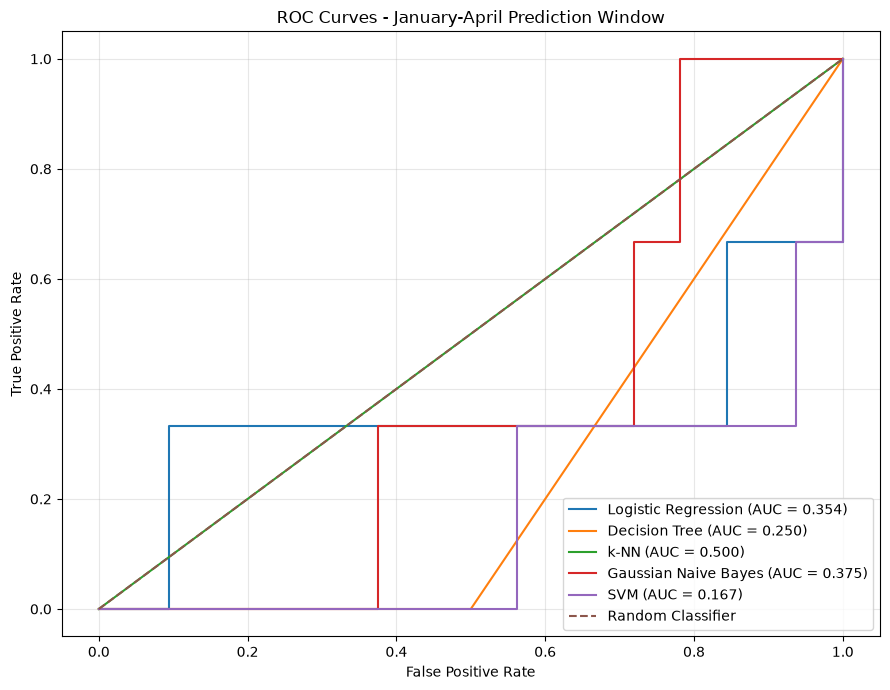

In [41]:
from sklearn.metrics import roc_curve, roc_auc_score, auc

plt.figure(figsize=(9, 7))

for name, model in models.items():

    # Train model
    model.fit(X_train_jan_apr, y_train)

    # Obtain continuous prediction scores
    if name == "SVM":
        scores = model.decision_function(X_test_jan_apr)
    else:
        scores = model.predict_proba(X_test_jan_apr)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, scores)

    # Calculate AUC
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

# Random classification baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves - January-April Prediction Window")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/08_jan_apr_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [2]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import recall_score, f1_score, roc_auc_score
from sklearn.dummy import DummyClassifier

# Reload labelled dataset
df = pd.read_csv("../data/processed/kerala_flood_labelled.csv")
df = df.sort_values("YEAR").reset_index(drop=True)

# Recreate chronological split
split_index = round(len(df) * 0.70)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

# Target variables
y_train = train_df["FLOOD"]
y_test = test_df["FLOOD"]

# January-May features
X_train = train_df[["JAN", "FEB", "MAR", "APR", "MAY"]]
X_test = test_df[["JAN", "FEB", "MAR", "APR", "MAY"]]

# January-March features
X_train_jan_mar = train_df[["JAN", "FEB", "MAR"]]
X_test_jan_mar = test_df[["JAN", "FEB", "MAR"]]

# January-April features
X_train_jan_apr = train_df[["JAN", "FEB", "MAR", "APR"]]
X_test_jan_apr = test_df[["JAN", "FEB", "MAR", "APR"]]

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Variables restored successfully!")

Variables restored successfully!


In [3]:
from sklearn.dummy import DummyClassifier

# Create majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Define prediction windows
windows = {
    "January-March": (
        X_train_jan_mar, X_test_jan_mar
    ),
    "January-April": (
        X_train_jan_apr, X_test_jan_apr
    ),
    "January-May": (
        X_train, X_test
    )
}

baseline_results = []

for window_name, (X_tr, X_te) in windows.items():

    # Cross-validation
    cv_result = cross_validate(
        dummy_model,
        X_tr,
        y_train,
        cv=cv,
        scoring=scoring
    )

    # Train on complete training data
    dummy_model.fit(X_tr, y_train)

    # Test predictions
    predictions = dummy_model.predict(X_te)
    probabilities = dummy_model.predict_proba(X_te)[:, 1]

    baseline_results.append({
        "Prediction_Window": window_name,
        "CV_Recall": cv_result["test_recall"].mean(),
        "CV_F1": cv_result["test_f1"].mean(),
        "CV_ROC_AUC": cv_result["test_roc_auc"].mean(),
        "Test_Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Test_F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Test_ROC_AUC": roc_auc_score(
            y_test, probabilities
        )
    })

baseline_summary = pd.DataFrame(baseline_results)

print(baseline_summary.round(3).to_string(index=False))

Prediction_Window  CV_Recall  CV_F1  CV_ROC_AUC  Test_Recall  Test_F1  Test_ROC_AUC
    January-March        0.0    0.0         0.5          0.0      0.0           0.5
    January-April        0.0    0.0         0.5          0.0      0.0           0.5
      January-May        0.0    0.0         0.5          0.0      0.0           0.5


In [4]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Fit majority-class baseline
dummy_model.fit(X_train, y_train)

# Predict on the test set
dummy_predictions = dummy_model.predict(X_test)

print(
    "Test Accuracy:",
    accuracy_score(y_test, dummy_predictions)
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        dummy_predictions,
        labels=[0, 1]
    )
)

Test Accuracy: 0.9142857142857143

Confusion Matrix:
[[32  0]
 [ 3  0]]


In [5]:
baseline_summary.to_csv(
    "../results/majority_class_baseline.csv",
    index=False
)

print("Baseline results saved successfully!")

Baseline results saved successfully!
